In [1]:
# ---- Importing Media --- #
from media import medium_helper

SiN = medium_helper.get_medium(
    "si3n4",
    (0.600, 1.200),
)

SiO2 = medium_helper.get_medium(
    "sio2",
    (0.600, 1.200)
)

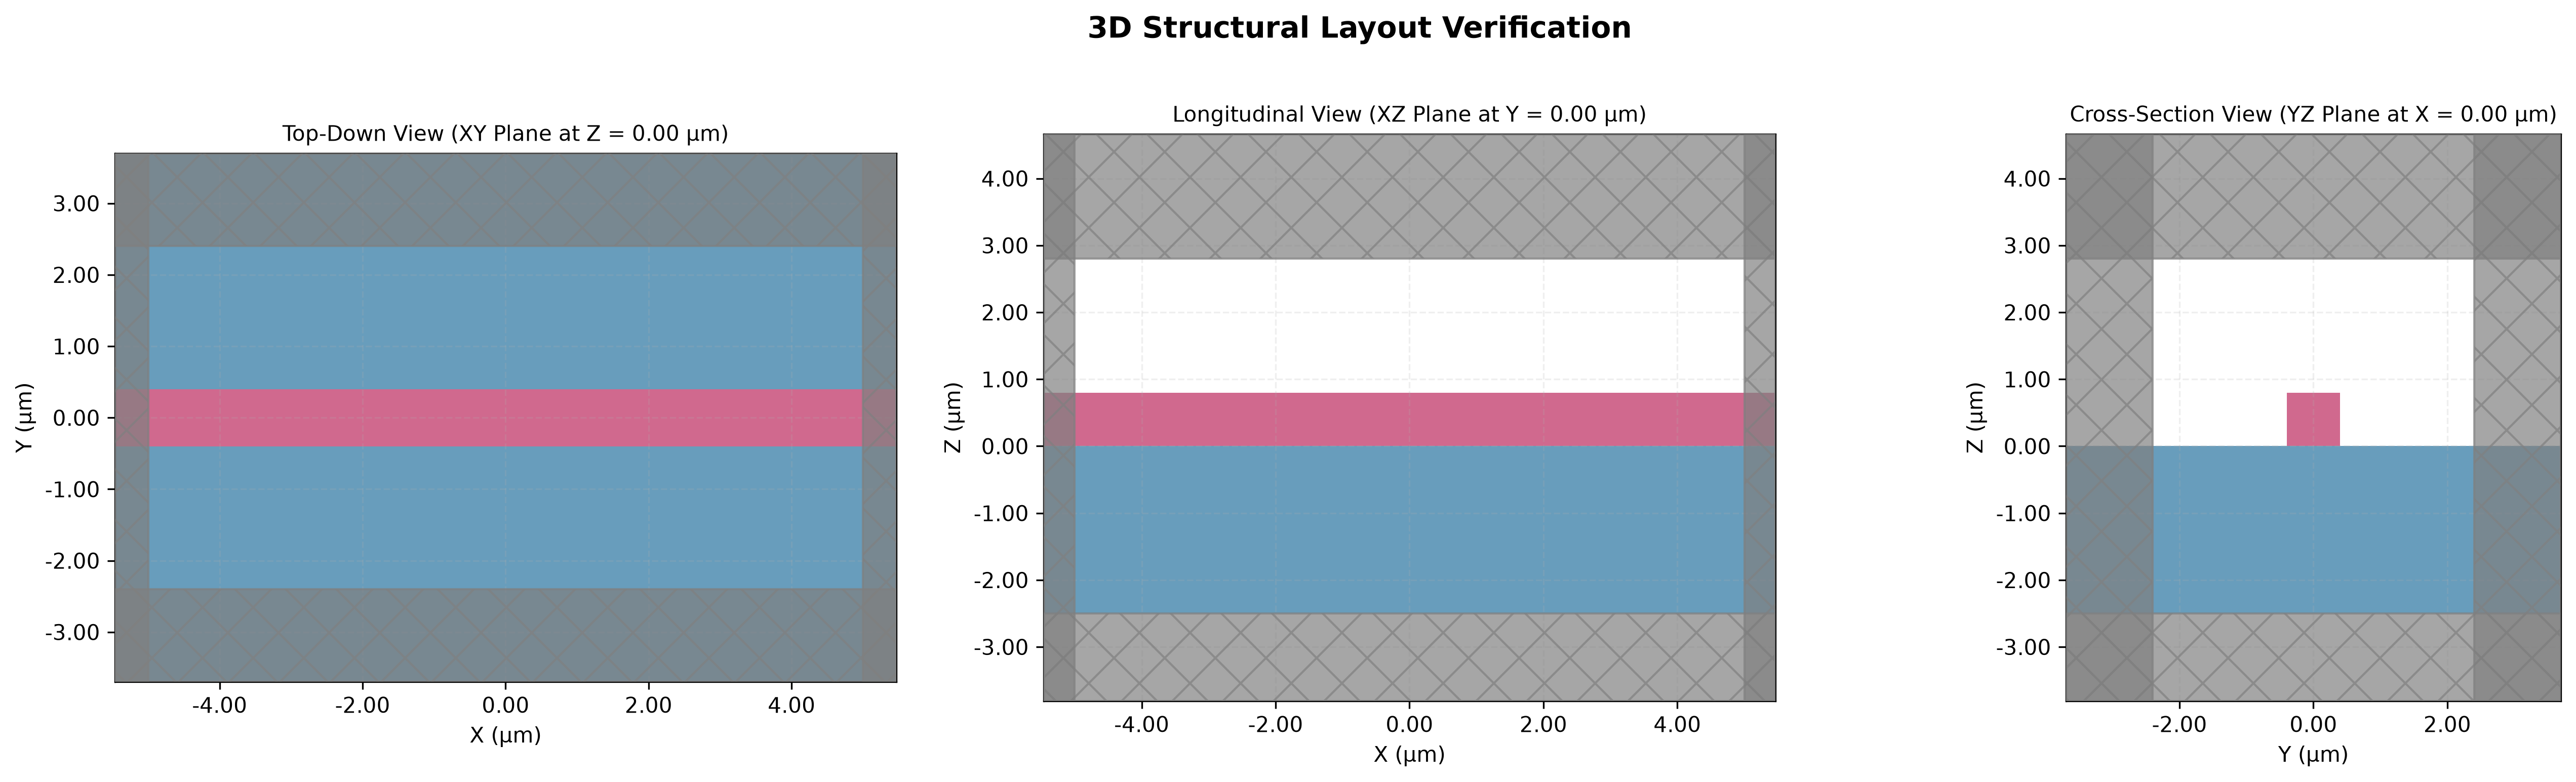

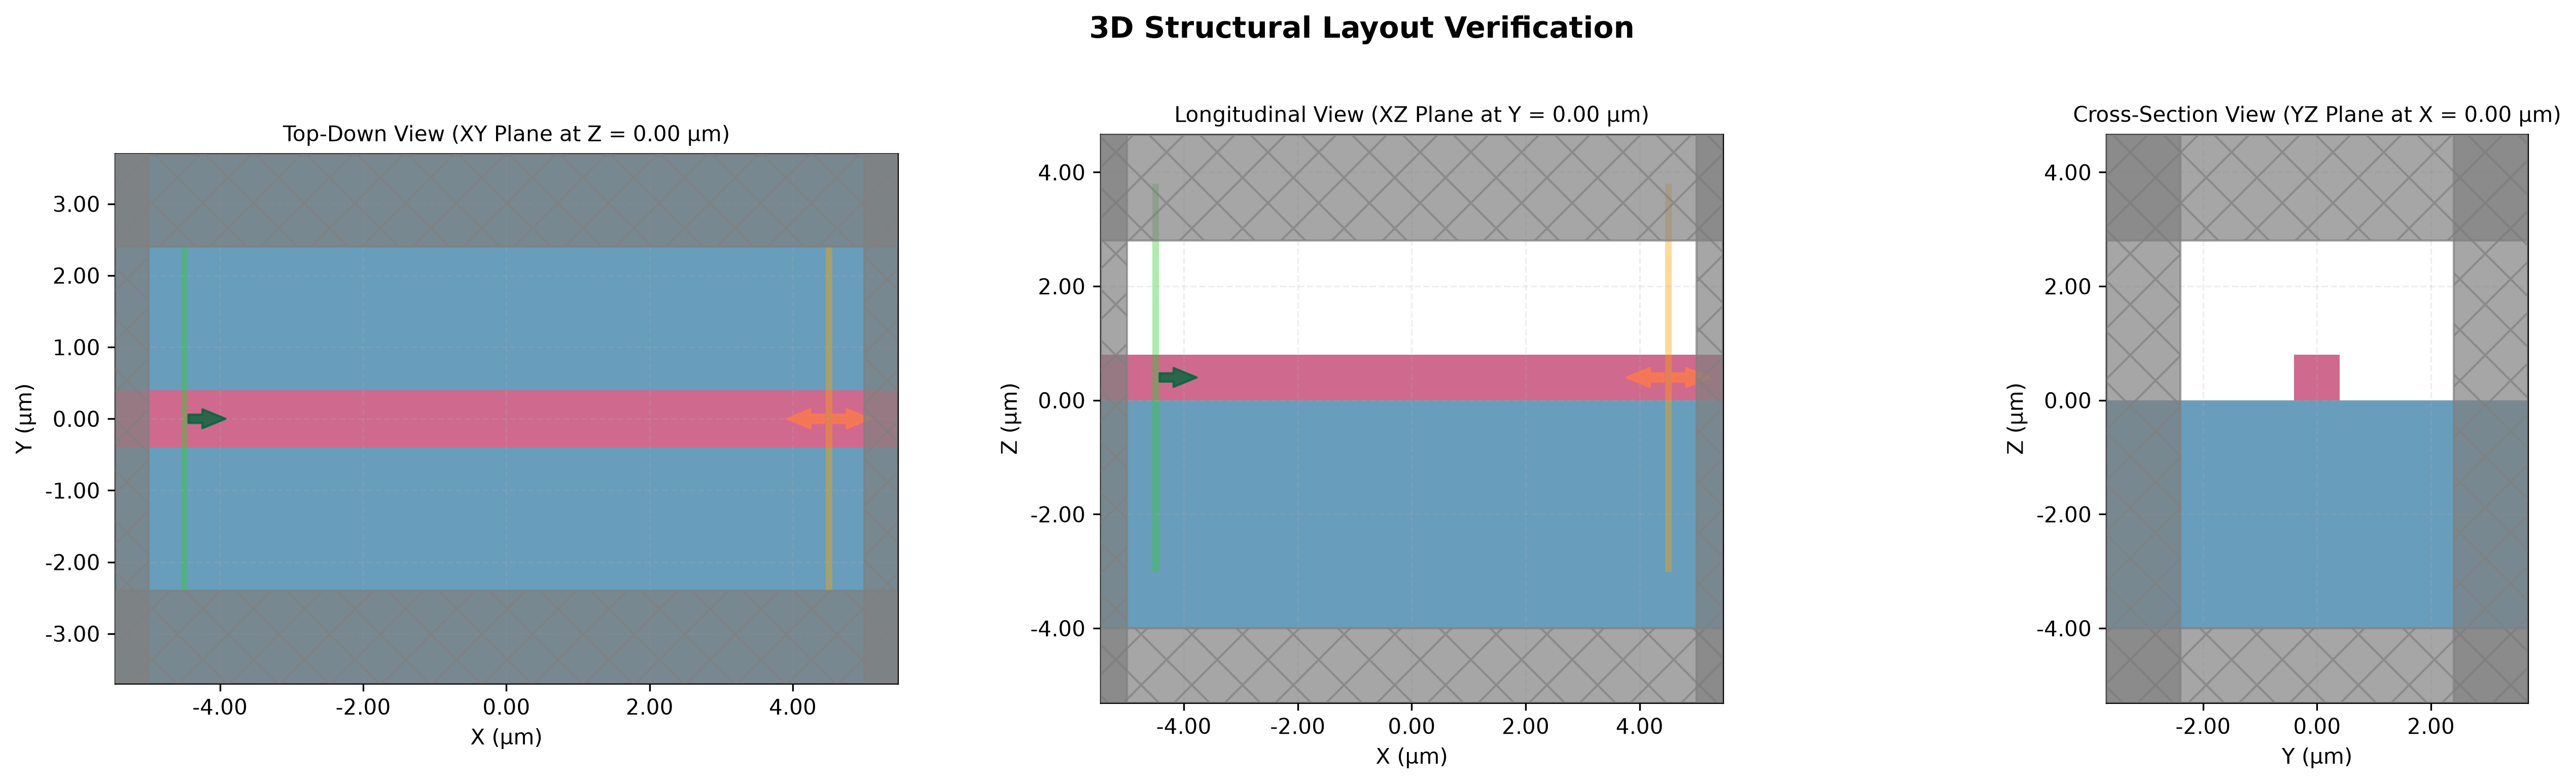

In [4]:
# ---- Waveguide Geometry Tests ---- #
from geometries import ridge_waveguide
from utilities import sim_plotter

from pathlib import Path 

example_passive_waveguide = ridge_waveguide.get_passive_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,
    
    substrate_height = 2.5,
    
    core_medium=SiN,
    sub_medium=SiO2,
)

# The active ridge waveguide features a mode source and a mode monitor
# which the passive simulation otherwise lacks.
example_active_waveguide = ridge_waveguide.get_active_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,

    substrate_height = 4.0,
    
    core_medium=SiN,
    sub_medium=SiO2,
)

# ---- Plotting to Verify Geometry ---- #
sim_plotter.display_3d(example_passive_waveguide, output_path = Path("example_passive_waveguide"), show = True)
sim_plotter.display_3d(example_active_waveguide, output_path = Path("example_active_waveguide"), show = True)

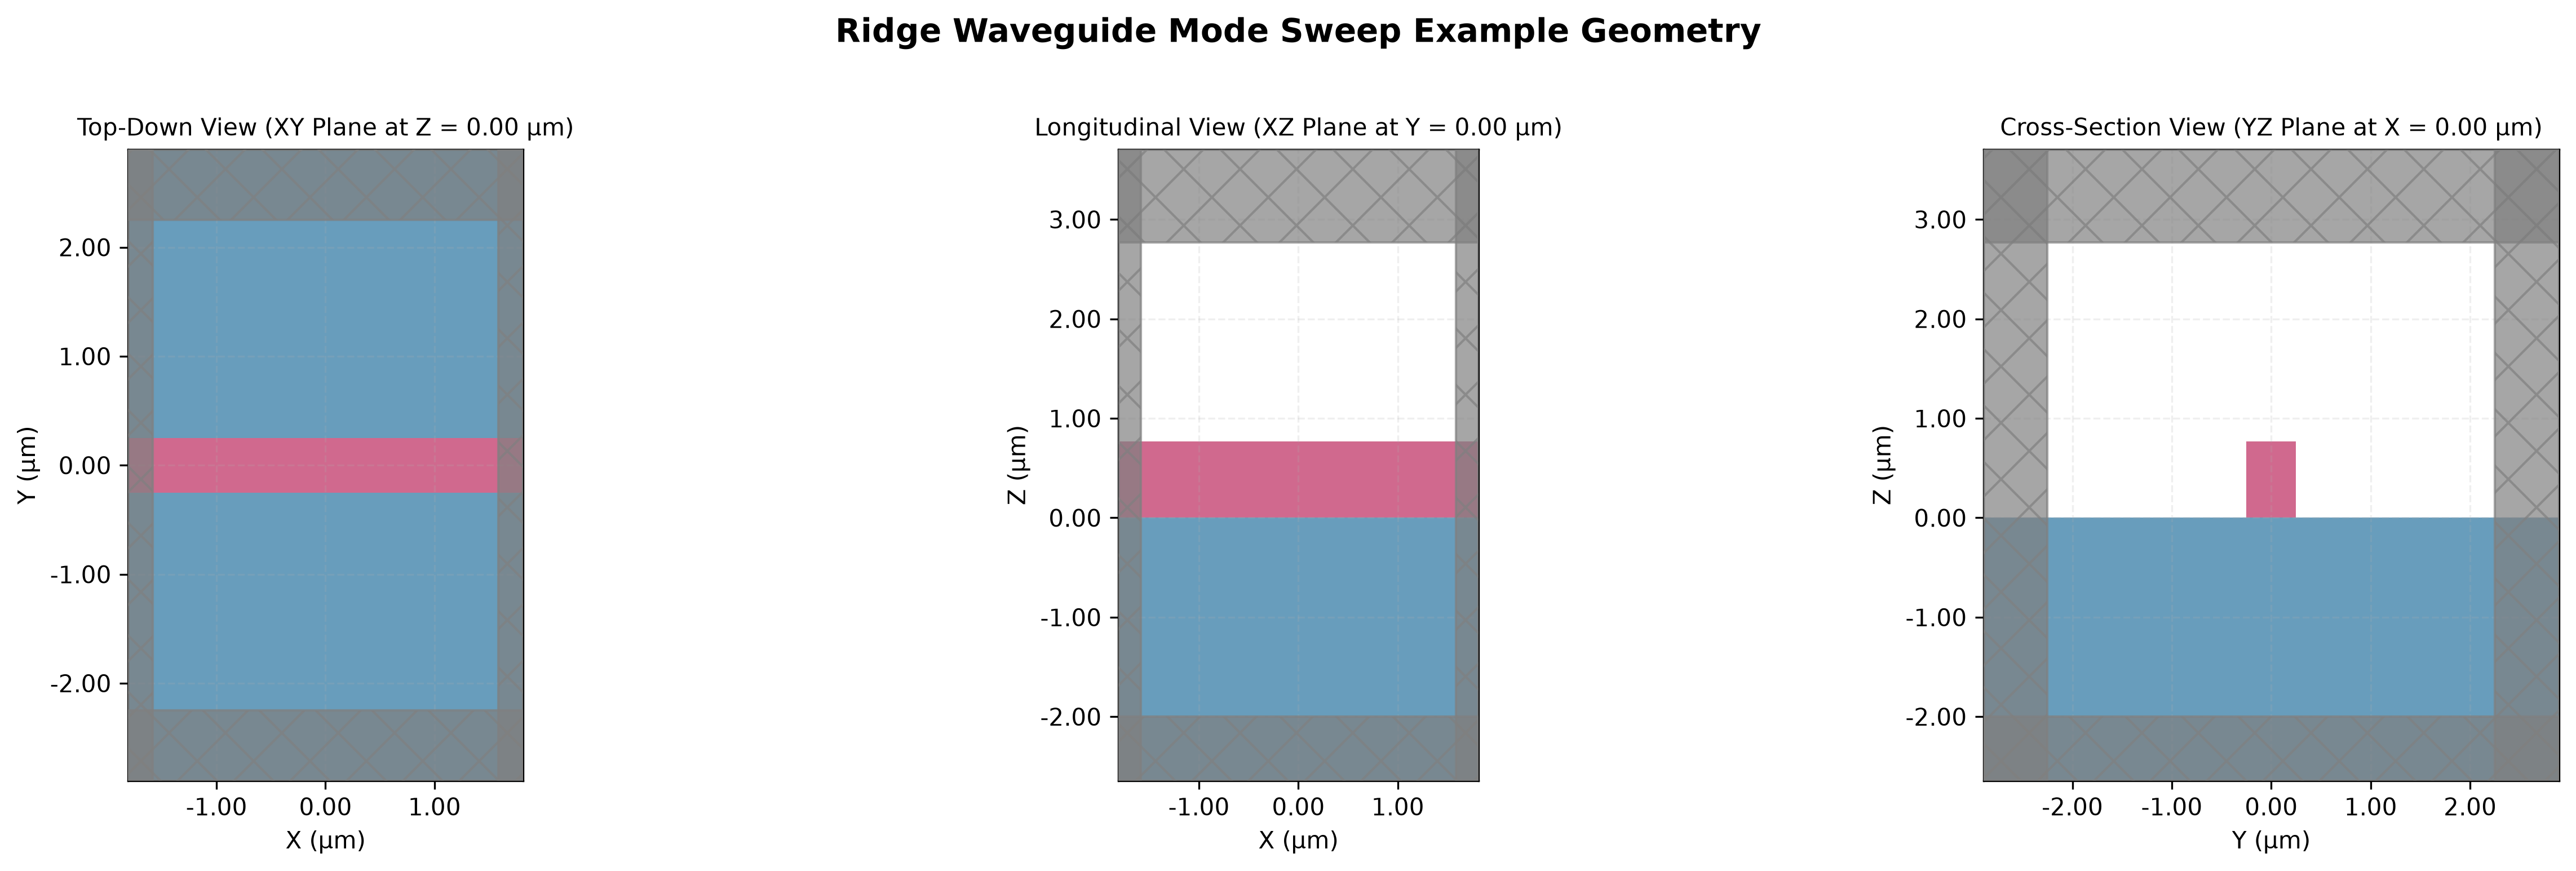

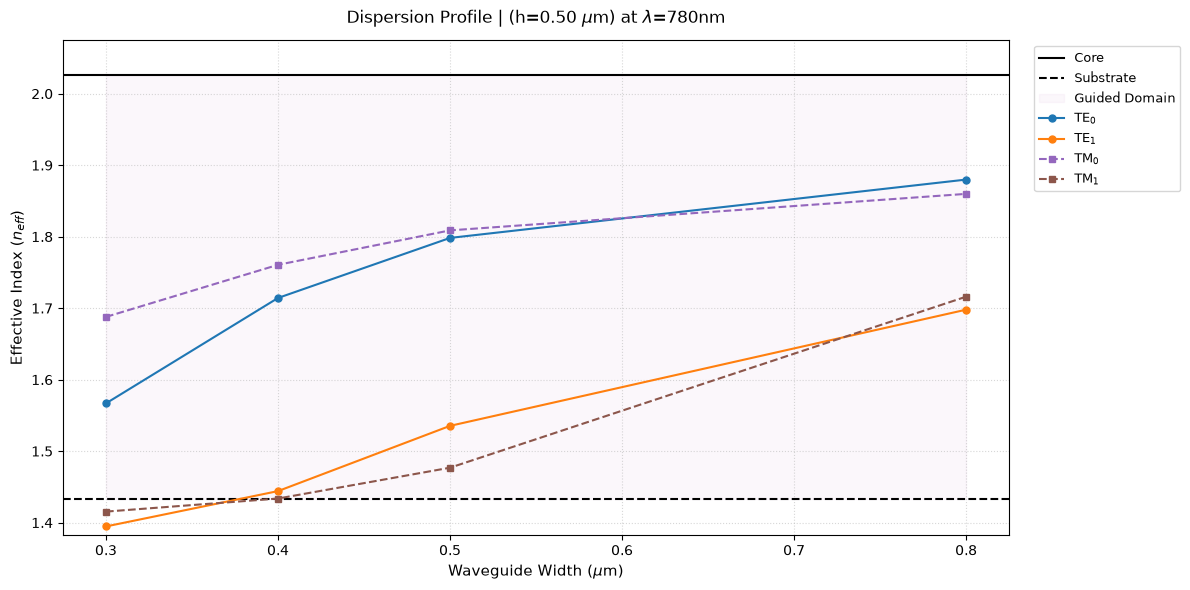

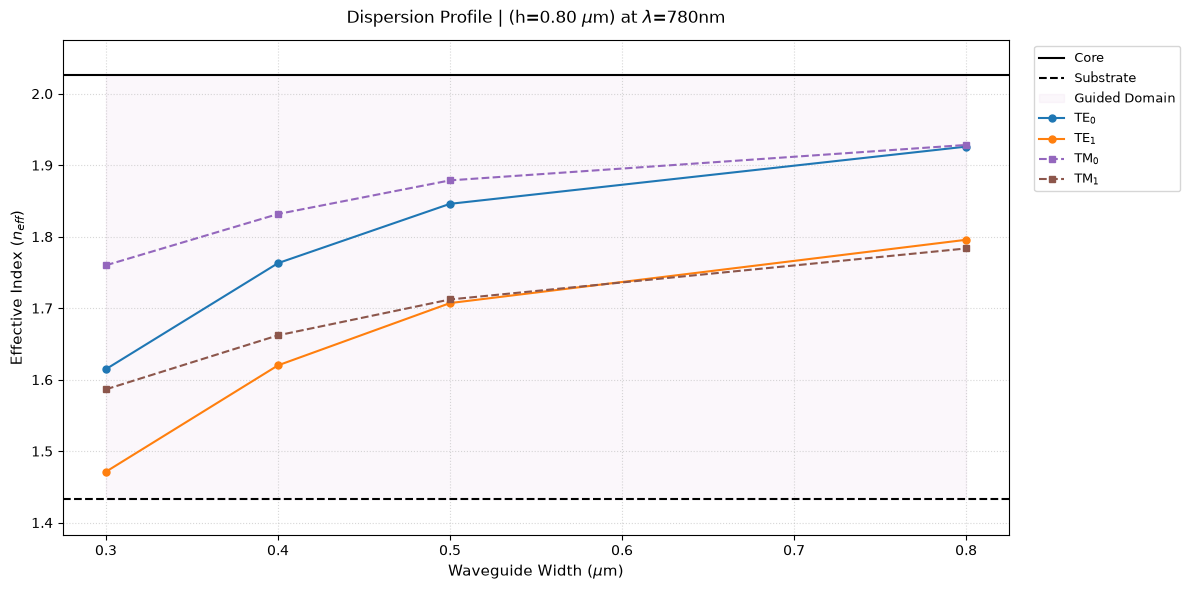

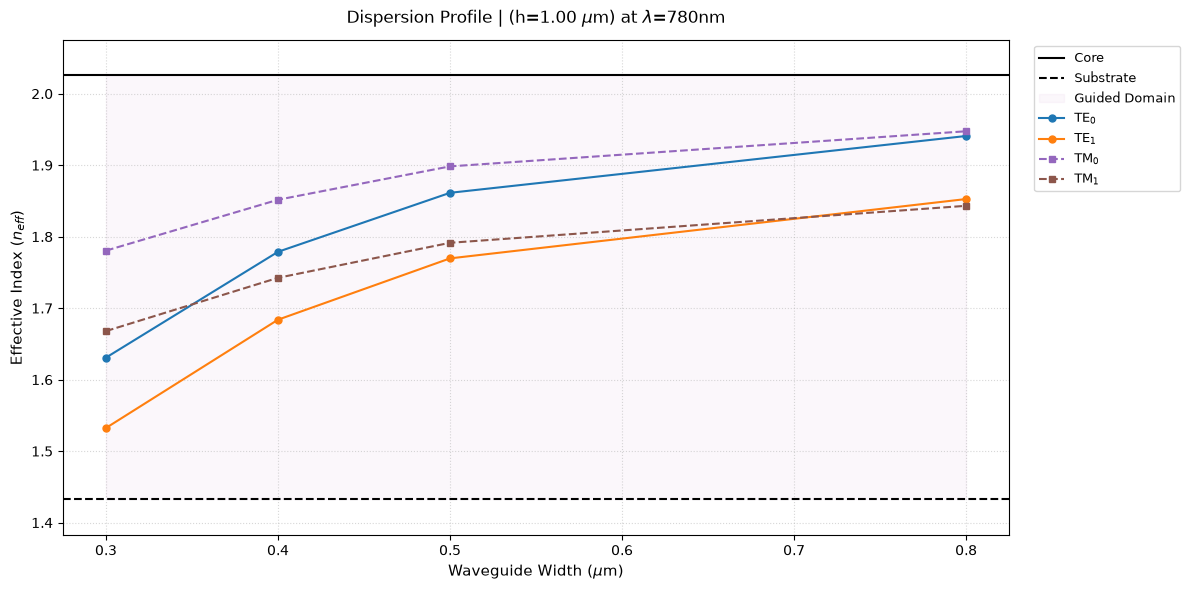

In [ ]:
# ---- Waveguide Mode Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points|
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the modes_in_geometry function
waveguide.modes_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/mode_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0   # Height of the substrate aka the BOX (in microns)
    num_modes       = 4,    # Number of modes computed by the Tidy3D solver

    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

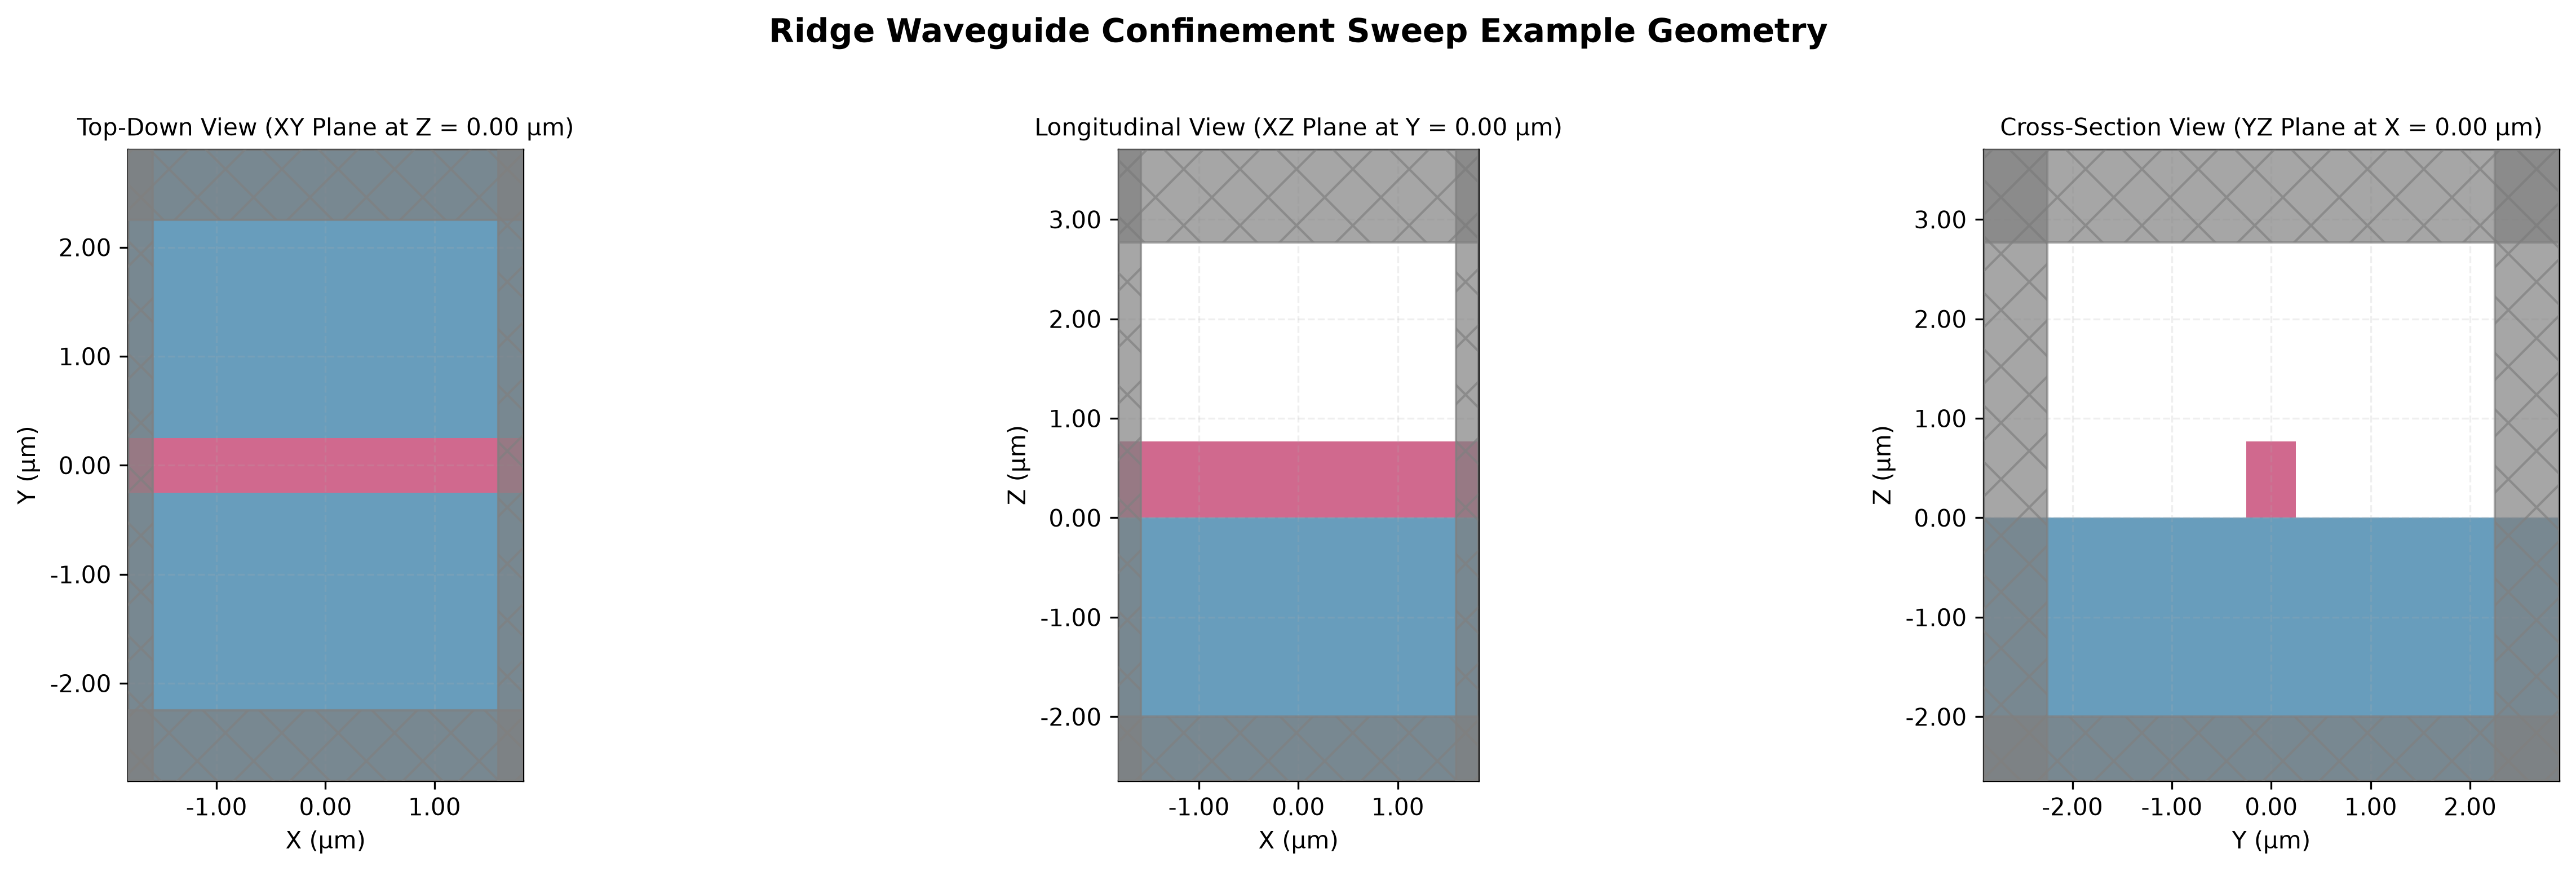

    [Confinement] Running geometric width sweep for fixed H = 0.500 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 58.6%, A_eff = 1.955 μm²
    [Confinement] Width 0.40 μm: Gamma = 77.6%, A_eff = 1.736 μm²
    [Confinement] Width 0.50 μm: Gamma = 88.1%, A_eff = 1.725 μm²
    [Confinement] Width 0.80 μm: Gamma = 93.8%, A_eff = 2.205 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H0.500um.png


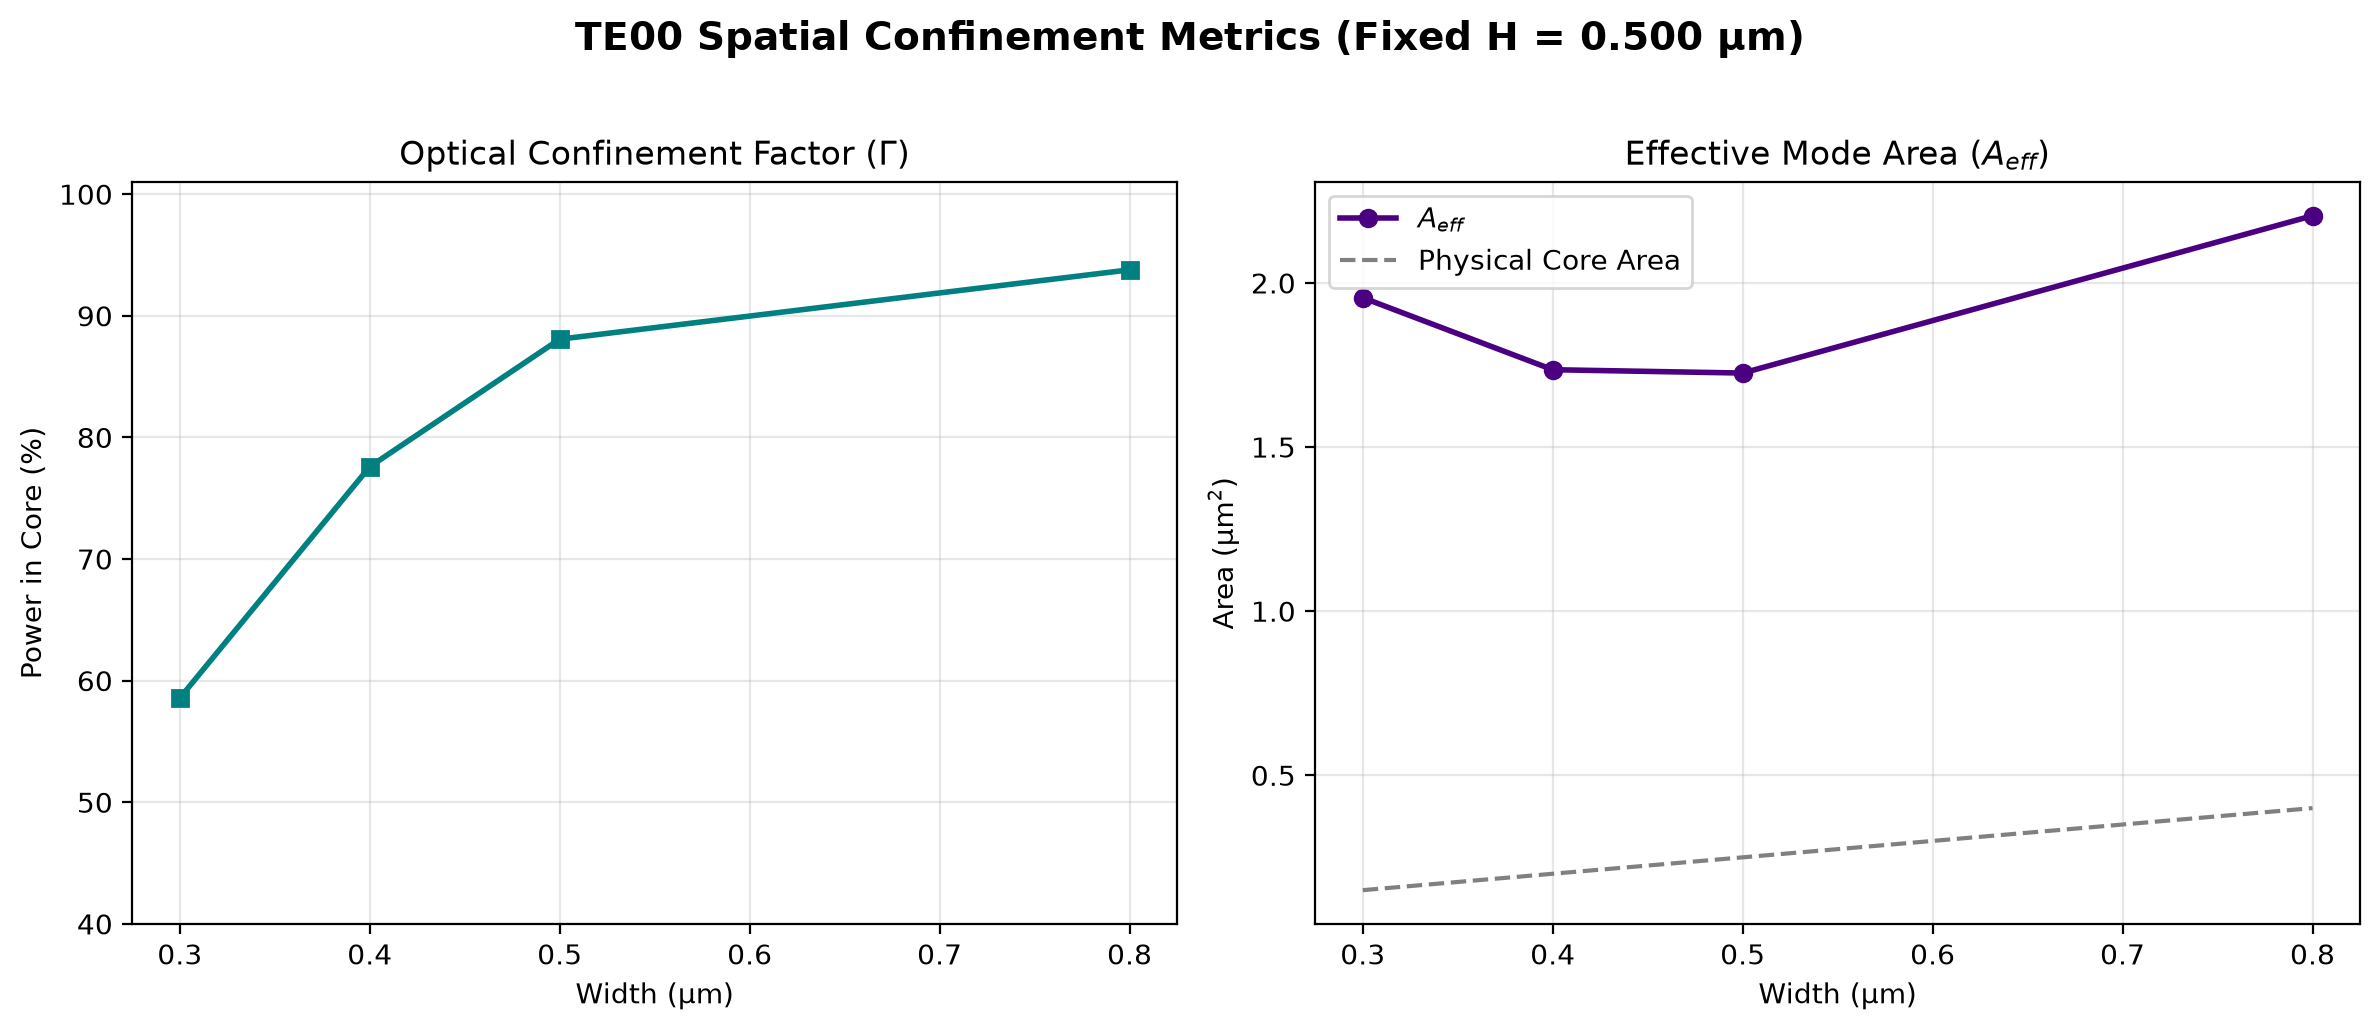

    [Confinement] Running geometric width sweep for fixed H = 0.800 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 62.8%, A_eff = 2.577 μm²
    [Confinement] Width 0.40 μm: Gamma = 80.8%, A_eff = 2.373 μm²
    [Confinement] Width 0.50 μm: Gamma = 90.9%, A_eff = 2.392 μm²
    [Confinement] Width 0.80 μm: Gamma = 96.3%, A_eff = 3.089 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H0.800um.png


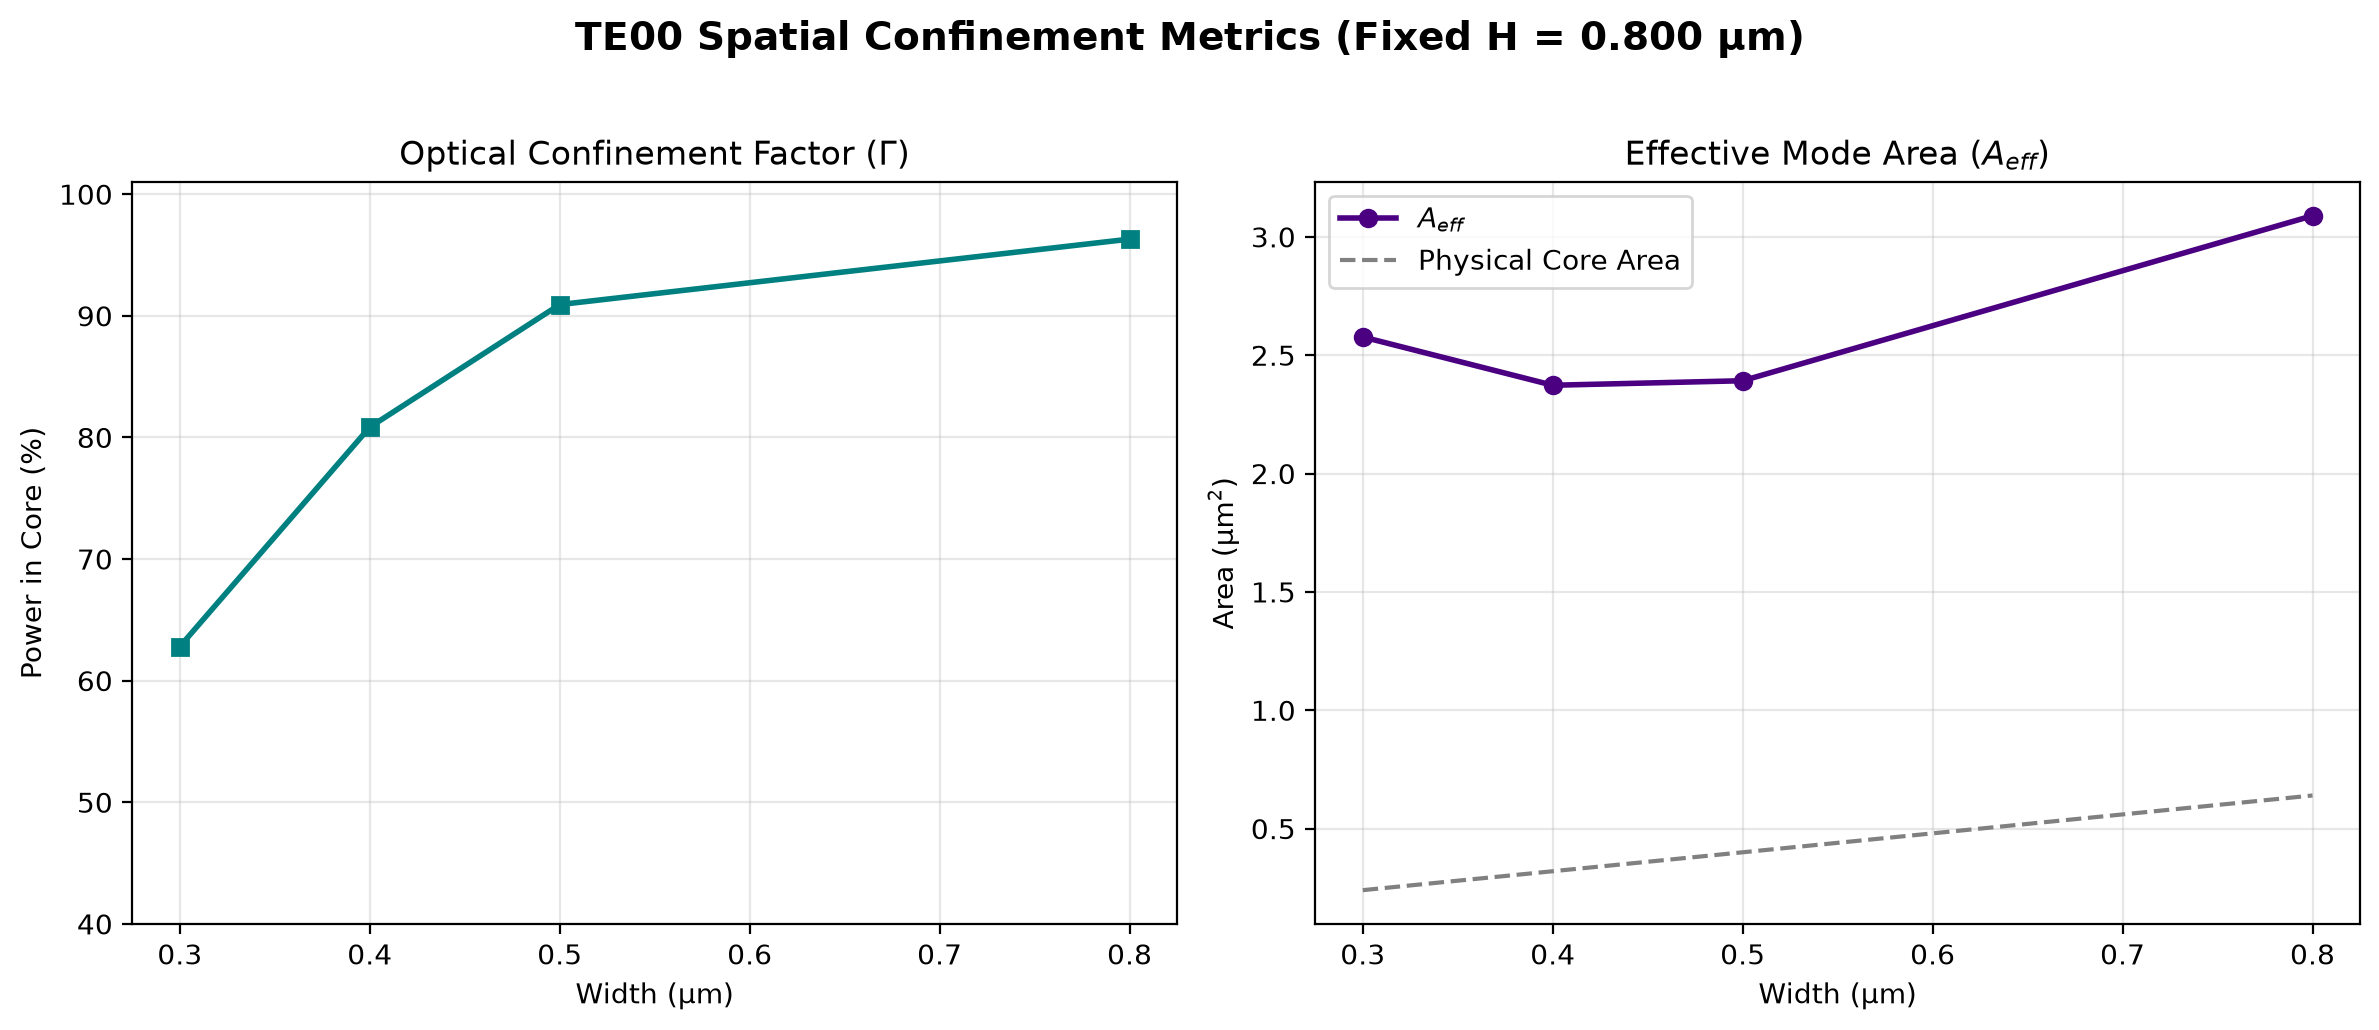

    [Confinement] Running geometric width sweep for fixed H = 1.000 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 63.8%, A_eff = 3.070 μm²
    [Confinement] Width 0.40 μm: Gamma = 81.6%, A_eff = 2.861 μm²
    [Confinement] Width 0.50 μm: Gamma = 91.6%, A_eff = 2.897 μm²
    [Confinement] Width 0.80 μm: Gamma = 96.9%, A_eff = 3.752 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H1.000um.png


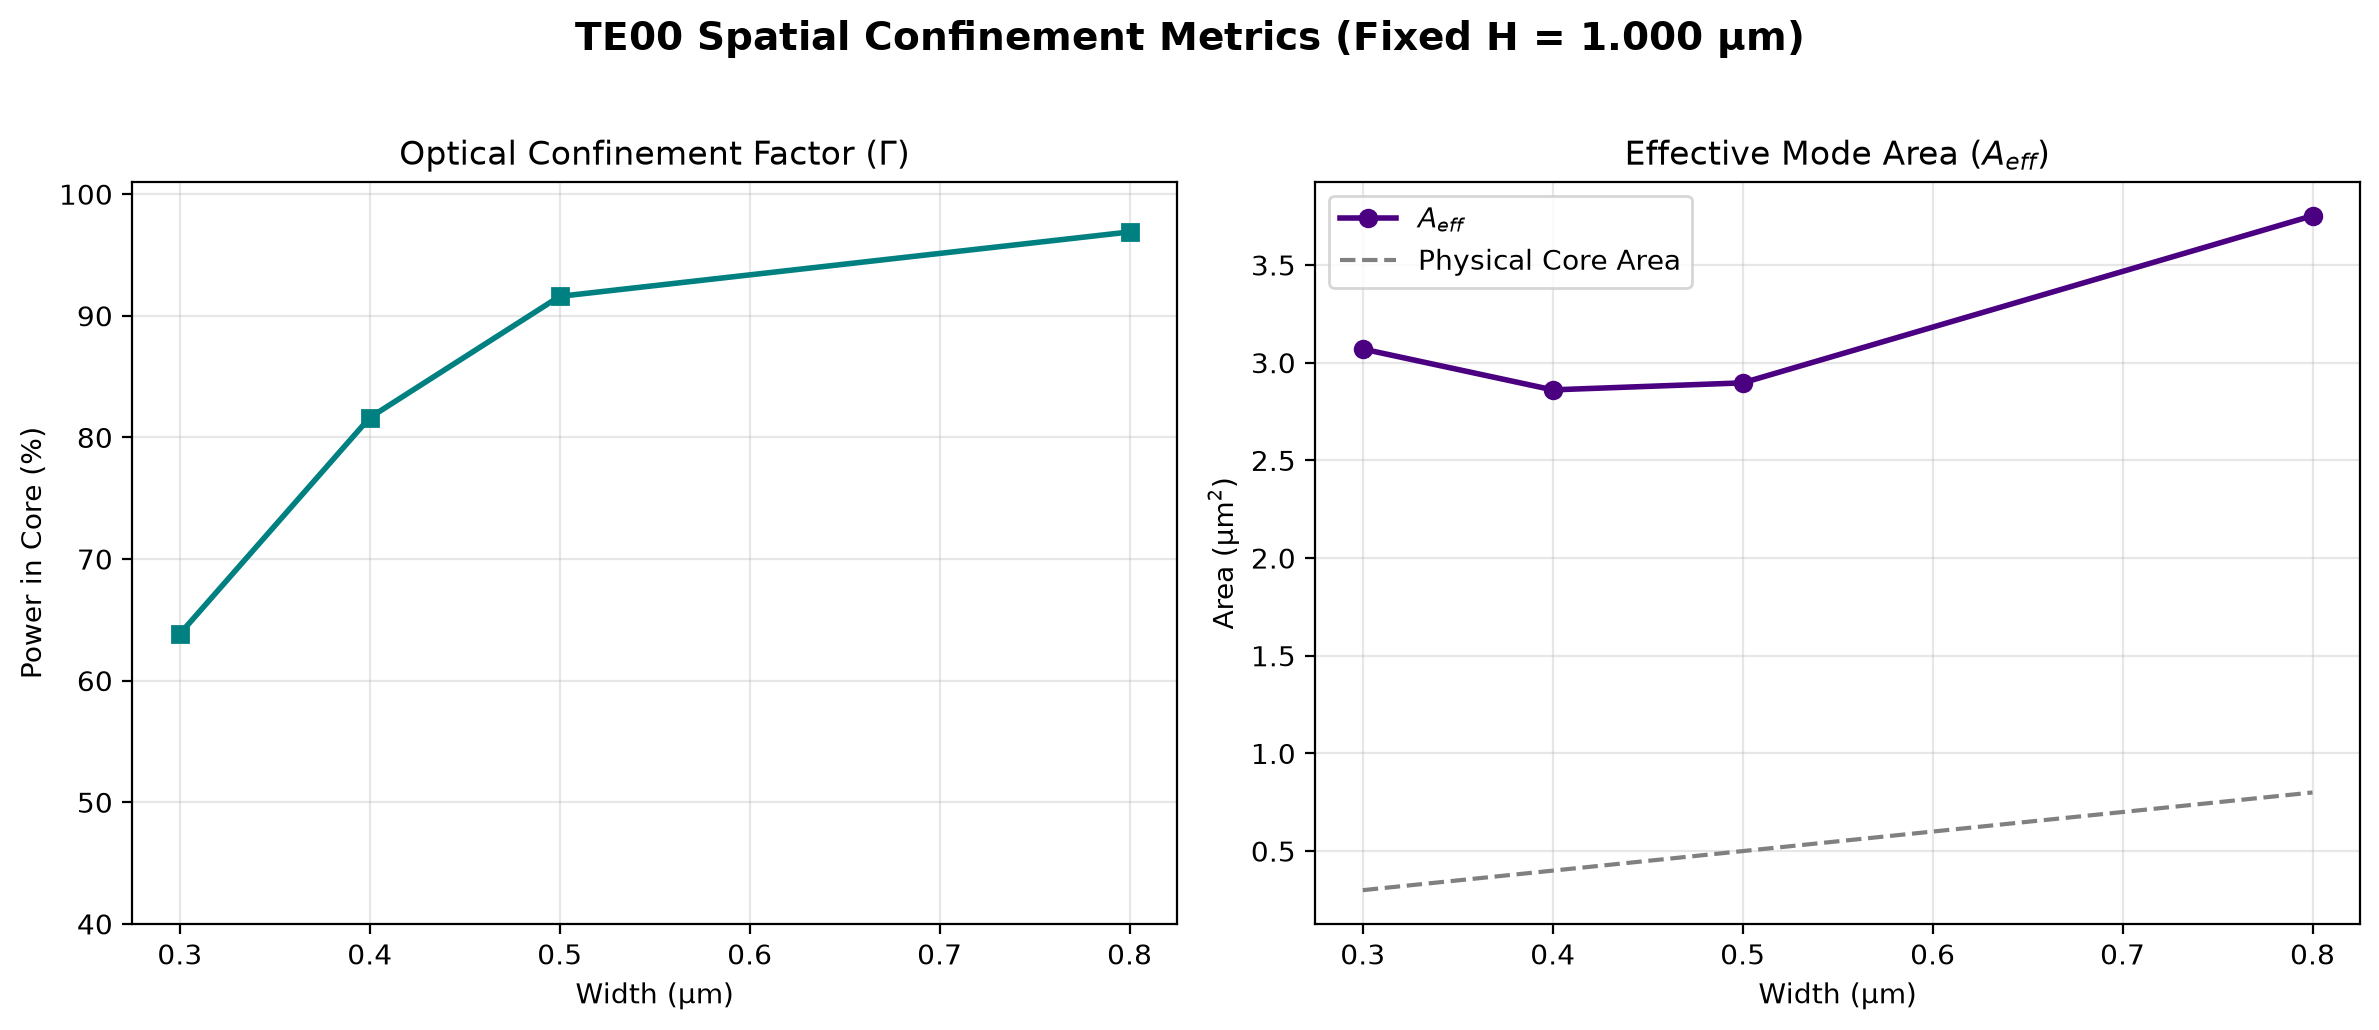

{0.5: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(58.57136065572593),
   np.float64(77.59189121344681),
   np.float64(88.07680226594503),
   np.float64(93.77875817941161)],
  [np.float64(1.9549219198394643),
   np.float64(1.7355764740700692),
   np.float64(1.7254099912221512),
   np.float64(2.2047127723584343)]),
 0.8: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(62.807302689750735),
   np.float64(80.84285538989175),
   np.float64(90.92283319648539),
   np.float64(96.30381180745825)],
  [np.float64(2.5770669054033593),
   np.float64(2.3730336965570427),
   np.float64(2.392117981932109),
   np.float64(3.08920926935165)]),
 1.0: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(63.84061354345288),
   np.float64(81.6256836568709),
   np.float64(91.59869749330129),
   np.float64(96.89342304946497)],
  [np.float64(3.0699304284331),
   np.float64(2.8608293194732752),
   np.float64(2.8966563116503914),
   np.float64(3.7521767935638004)])}

In [ ]:
# ---- Waveguide Confinement Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.confinement_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/confinement_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0   # Height of the substrate aka the BOX (in microns)
    
    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

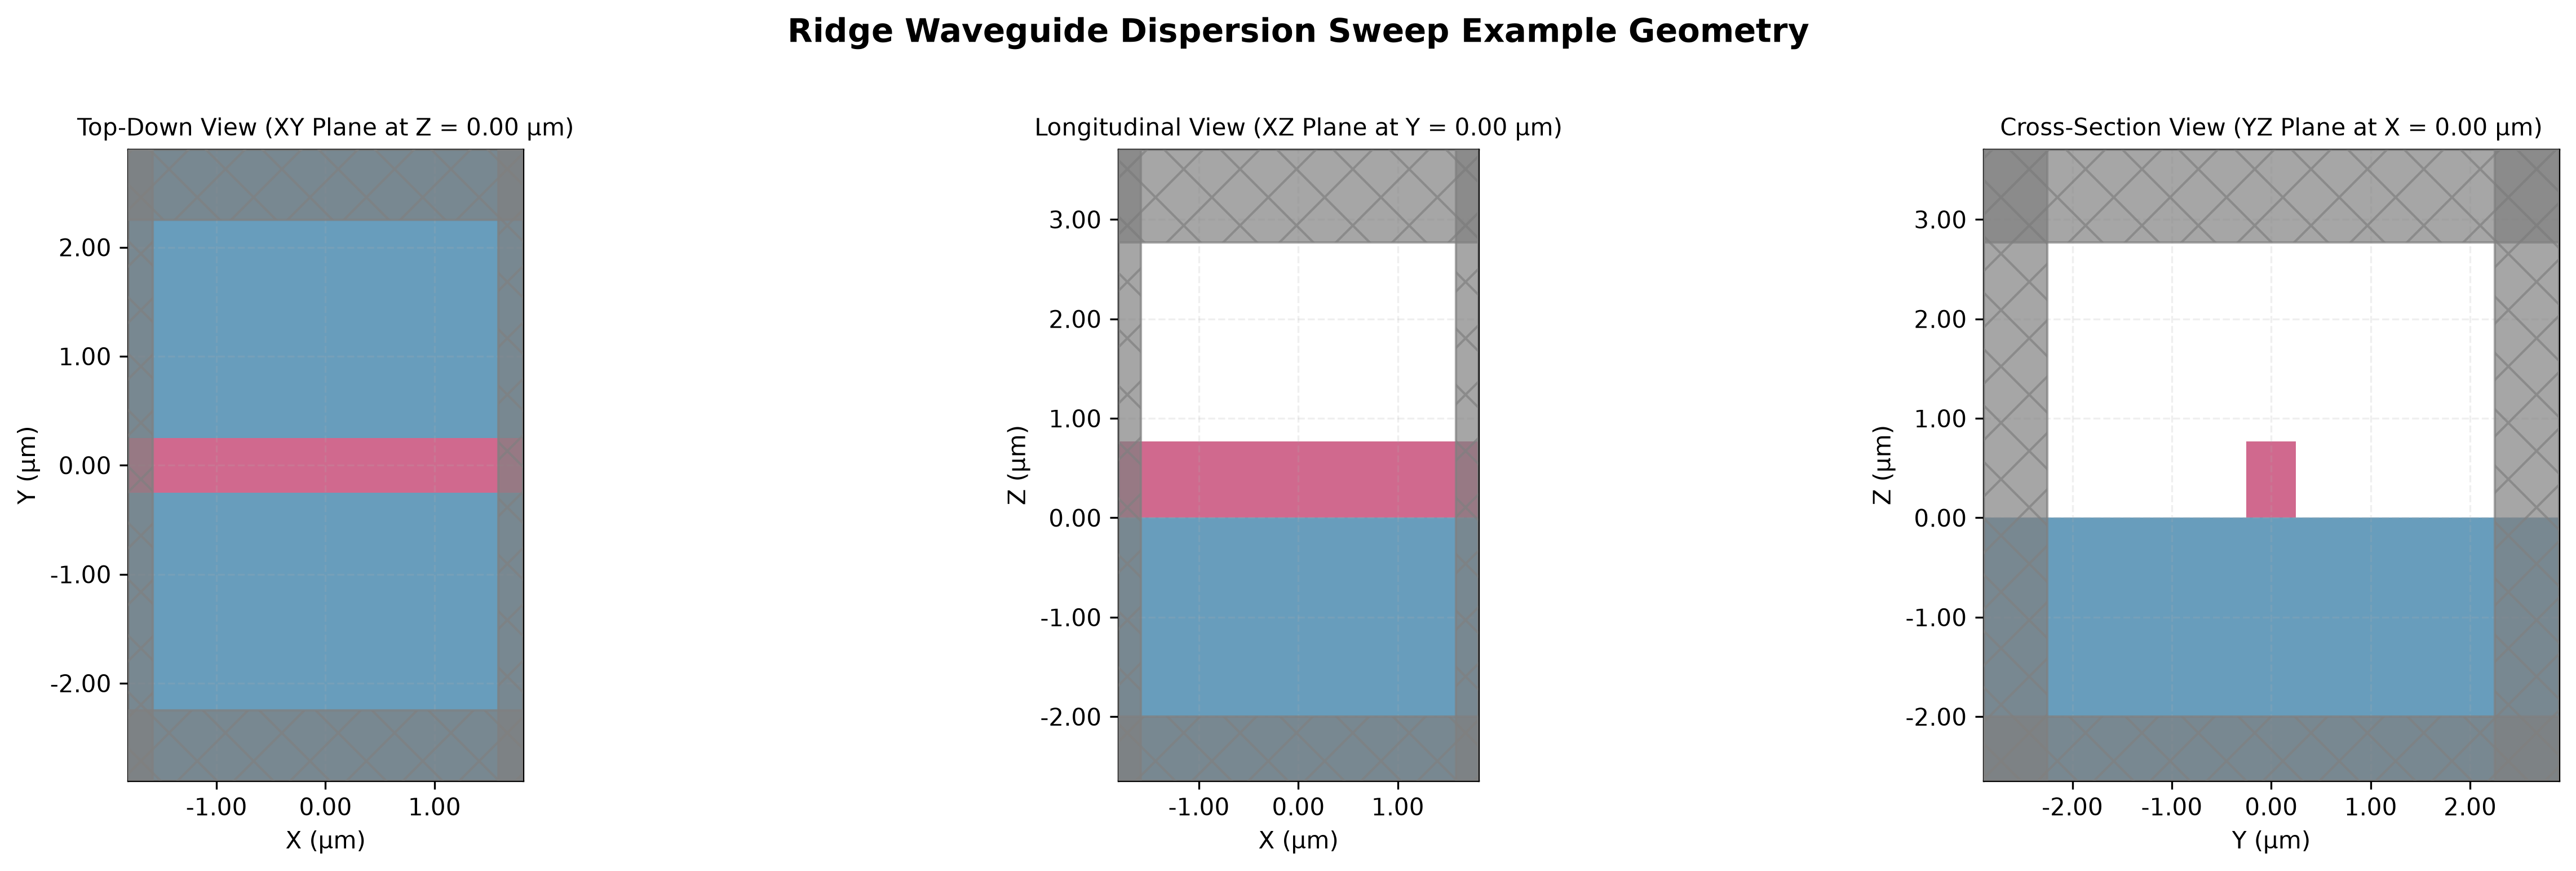

    [Dispersion] Sweeping heights for fixed W = 0.300 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = -14.80 ps/(nm·km) [SINGLE MODE]
    [Dispersion] Height 0.80 μm: D = 0.19 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 2.73 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.300um.png


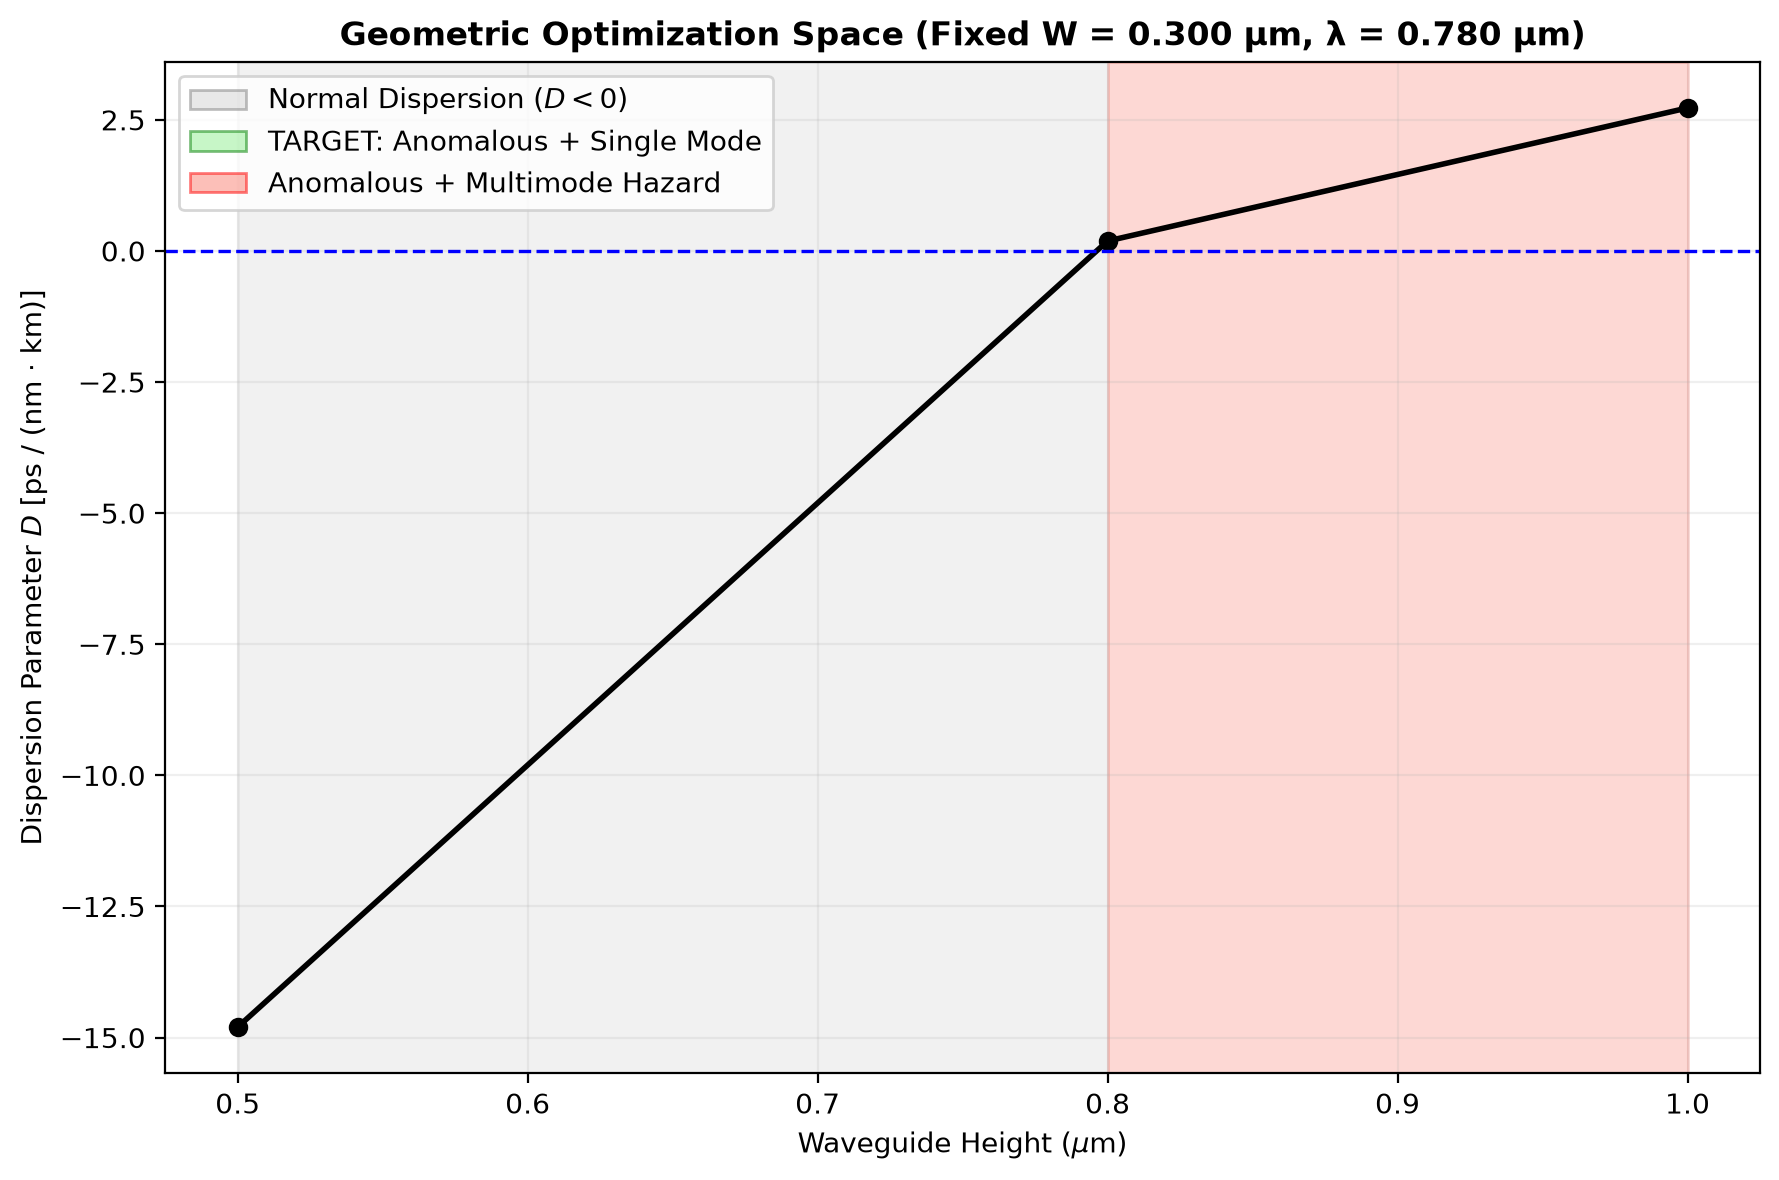

    [Dispersion] Sweeping heights for fixed W = 0.400 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 6.83 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 8.65 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 8.46 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.400um.png


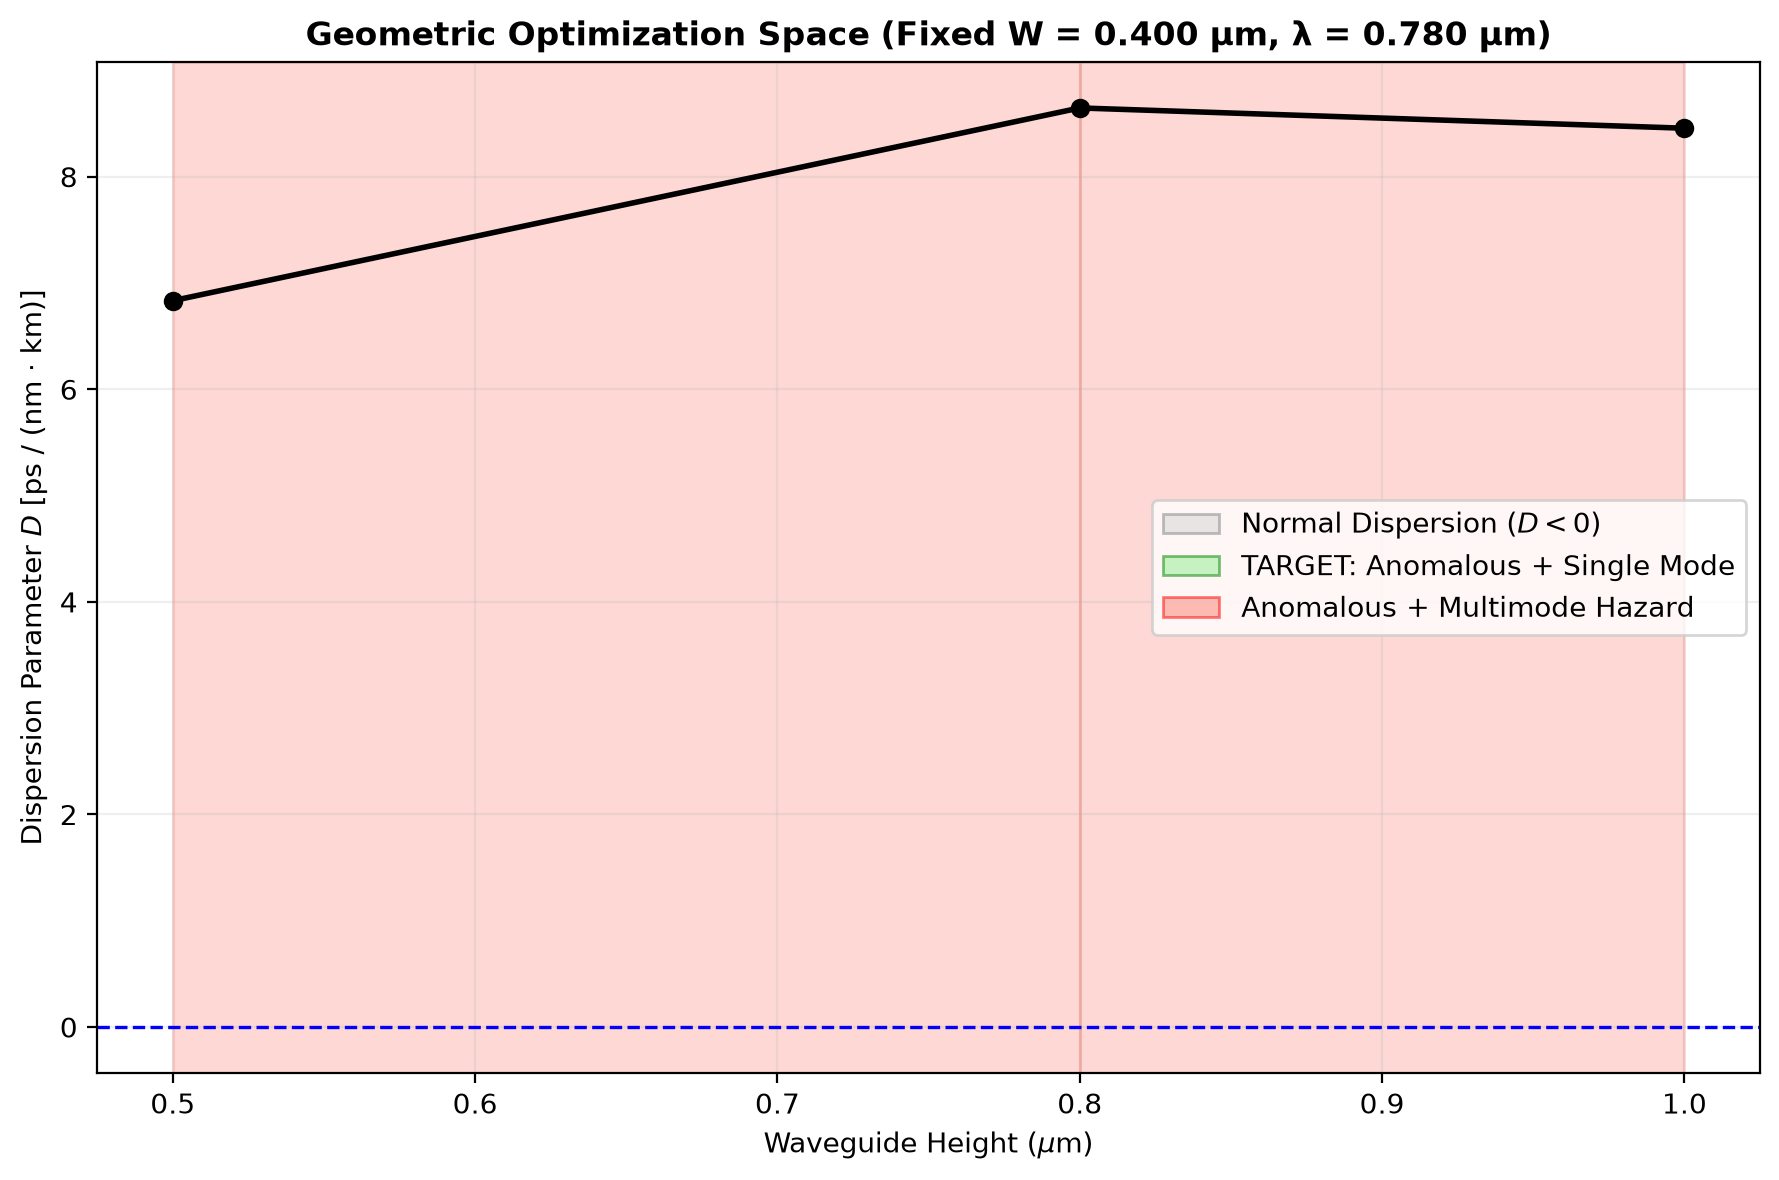

    [Dispersion] Sweeping heights for fixed W = 0.500 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 5.62 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 5.63 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 5.16 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.500um.png


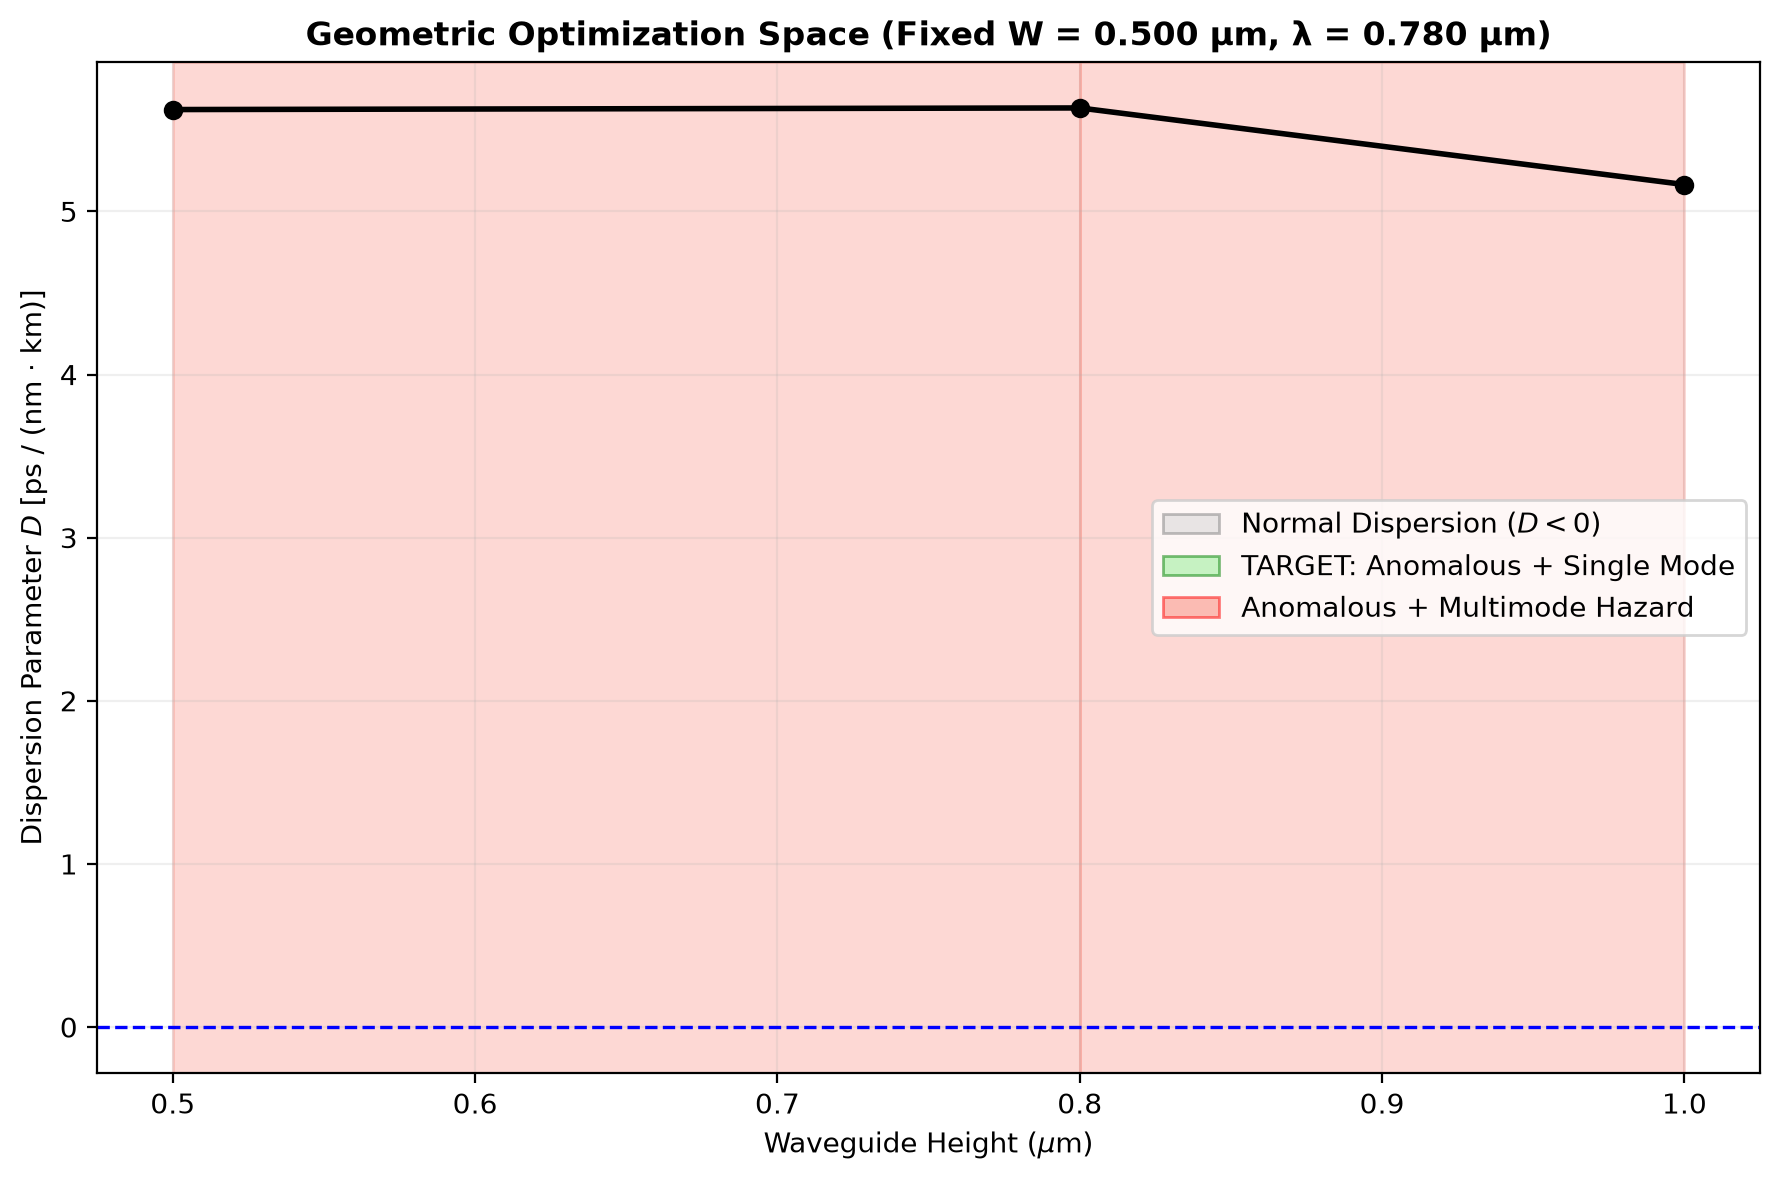

    [Dispersion] Sweeping heights for fixed W = 0.800 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 0.44 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 0.23 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = -0.18 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.800um.png


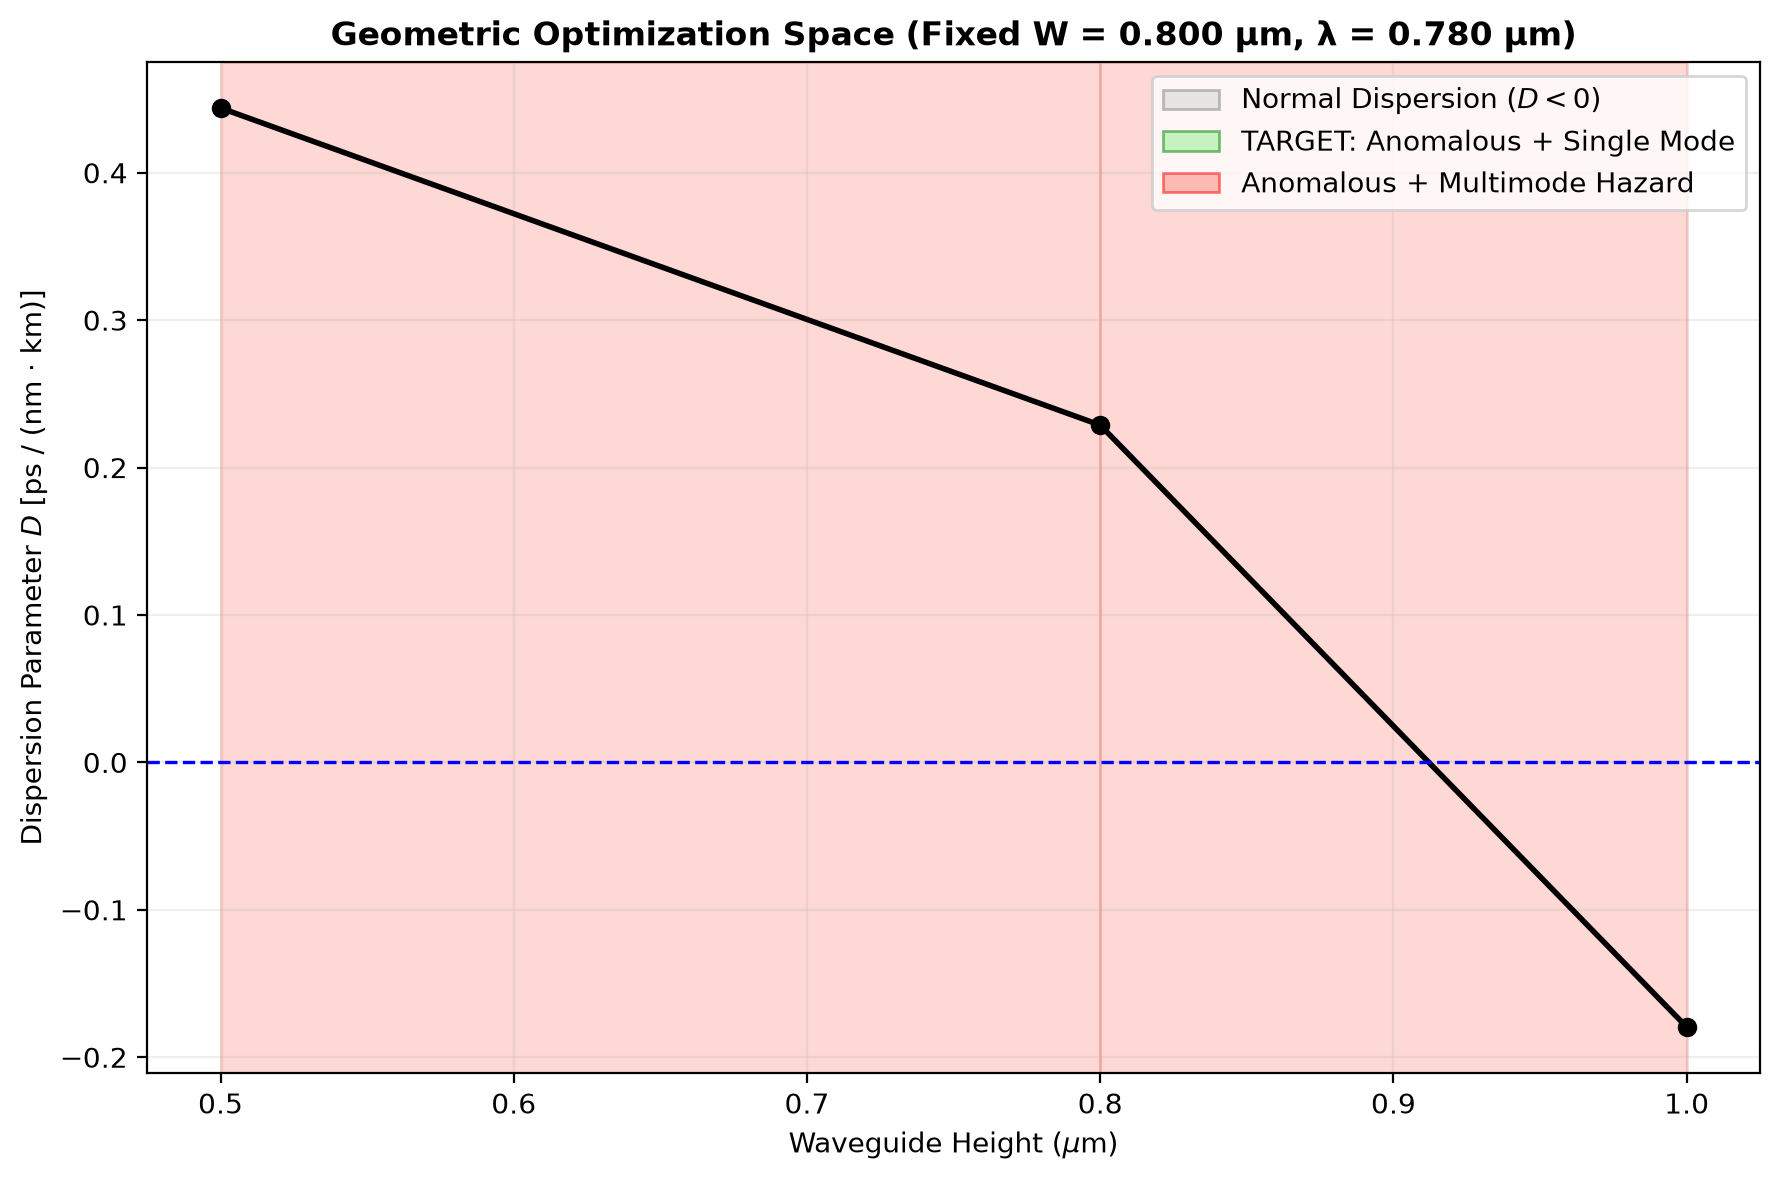

{0.3: ([0.5, 0.8, 1.0],
  [-14.799276615549726, 0.1890946183050169, 2.7263174494114253],
  [True, False, False]),
 0.4: ([0.5, 0.8, 1.0],
  [6.833234635769858, 8.646578531547783, 8.455808494788203],
  [False, False, False]),
 0.5: ([0.5, 0.8, 1.0],
  [5.624234587696865, 5.6341013972488385, 5.164476997213363],
  [False, False, False]),
 0.8: ([0.5, 0.8, 1.0],
  [0.4439384164597086, 0.22876268554787188, -0.1795512428687282],
  [False, False, False])}

In [ ]:
# ---- Waveguide Dispersion Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.dispersion_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/dispersion_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0   # Height of the substrate aka the BOX (in microns)
    
    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)